In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_dir = "../../data/"

target = pd.read_csv(data_dir + "train.csv")

book_train = pd.read_parquet(data_dir + "book_train.parquet")
book_train

,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2,stock_id
0,5,0,1.001422,1.002301,1.001370,1.002353,3,226,2,100,0
1,5,1,1.001422,1.002301,1.001370,1.002353,3,100,2,100,0
2,5,5,1.001422,1.002301,1.001370,1.002405,3,100,2,100,0
3,5,6,1.001422,1.002301,1.001370,1.002405,3,126,2,100,0
4,5,7,1.001422,1.002301,1.001370,1.002405,3,126,2,100,0
...,...,...,...,...,...,...,...,...,...,...,...
167253284,32767,589,0.999662,0.999797,0.999527,0.999932,400,600,400,528,99
167253285,32767,590,0.999662,0.999797,0.999527,0.999932,400,500,400,528,99
167253286,32767,592,0.999527,0.999797,0.999391,0.999932,900,600,600,528,99
167253287,32767,596,0.999527,0.999797,0.999391,0.999932,900,700,600,628,99


In [3]:
book_train.describe()

,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2
count,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08,1.672533e+08
mean,1.602237e+04,2.969969e+02,9.997217e-01,1.000274e+00,9.995276e-01,1.000470e+00,9.285549e+02,9.233744e+02,1.181631e+03,1.146534e+03
std,9.370937e+03,1.734195e+02,3.811545e-03,3.810885e-03,3.821979e-03,3.820810e-03,5.782958e+03,5.263738e+03,7.168244e+03,6.121242e+03
min,5.000000e+00,0.000000e+00,8.807735e-01,8.876458e-01,8.806137e-01,8.898833e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
25%,7.837000e+03,1.460000e+02,9.984497e-01,9.989405e-01,9.982569e-01,9.991112e-01,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02
50%,1.584500e+04,2.960000e+02,9.998062e-01,1.000211e+00,9.996397e-01,1.000380e+00,1.610000e+02,1.610000e+02,1.590000e+02,1.610000e+02
75%,2.395800e+04,4.470000e+02,1.001055e+00,1.001535e+00,1.000888e+00,1.001727e+00,4.000000e+02,3.970000e+02,5.000000e+02,5.000000e+02
max,3.276700e+04,5.990000e+02,1.125048e+00,1.127149e+00,1.124570e+00,1.127245e+00,1.051433e+06,6.462940e+05,9.801370e+05,8.501390e+05


In [4]:
book_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 167253289 entries, 0 to 167253288
Data columns (total 11 columns):
 #   Column             Dtype   
---  ------             -----   
 0   time_id            int16   
 1   seconds_in_bucket  int16   
 2   bid_price1         float32 
 3   ask_price1         float32 
 4   bid_price2         float32 
 5   ask_price2         float32 
 6   bid_size1          int32   
 7   ask_size1          int32   
 8   bid_size2          int32   
 9   ask_size2          int32   
 10  stock_id           category
dtypes: category(1), float32(4), int16(2), int32(4)
memory usage: 5.8 GB


In [5]:
book_train.isna().sum()

# 就是没有na，这个数据。

time_id              0
seconds_in_bucket    0
bid_price1           0
ask_price1           0
bid_price2           0
ask_price2           0
bid_size1            0
ask_size1            0
bid_size2            0
ask_size2            0
stock_id             0
dtype: int64

In [6]:
trade_train = pd.read_parquet(data_dir + "trade_train.parquet")
trade_train

,time_id,seconds_in_bucket,price,size,order_count,stock_id
0,5,21,1.002301,326,12,0
1,5,46,1.002778,128,4,0
2,5,50,1.002818,55,1,0
3,5,57,1.003155,121,5,0
4,5,68,1.003646,4,1,0
...,...,...,...,...,...,...
38382736,32767,570,0.999932,100,1,99
38382737,32767,575,0.999932,100,1,99
38382738,32767,579,0.999797,300,3,99
38382739,32767,584,0.999854,172,2,99


In [7]:
example = book_train.query("time_id == 5 and stock_id == 0")
example

,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2,stock_id
0,5,0,1.001422,1.002301,1.001370,1.002353,3,226,2,100,0
1,5,1,1.001422,1.002301,1.001370,1.002353,3,100,2,100,0
2,5,5,1.001422,1.002301,1.001370,1.002405,3,100,2,100,0
3,5,6,1.001422,1.002301,1.001370,1.002405,3,126,2,100,0
4,5,7,1.001422,1.002301,1.001370,1.002405,3,126,2,100,0
...,...,...,...,...,...,...,...,...,...,...,...
297,5,585,1.003129,1.003749,1.003025,1.003801,100,3,26,3,0
298,5,586,1.003129,1.003749,1.002612,1.003801,100,3,2,3,0
299,5,587,1.003129,1.003749,1.003025,1.003801,100,3,26,3,0
300,5,588,1.003129,1.003749,1.002612,1.003801,100,3,2,3,0


In [8]:
example2 = trade_train.query("time_id == 5 and stock_id == 0")
example2

,time_id,seconds_in_bucket,price,size,order_count,stock_id
0,5,21,1.002301,326,12,0
1,5,46,1.002778,128,4,0
2,5,50,1.002818,55,1,0
3,5,57,1.003155,121,5,0
4,5,68,1.003646,4,1,0
5,5,78,1.003762,134,5,0
6,5,122,1.004207,102,3,0
7,5,127,1.004577,1,1,0
8,5,144,1.004370,6,1,0
9,5,147,1.003964,233,4,0


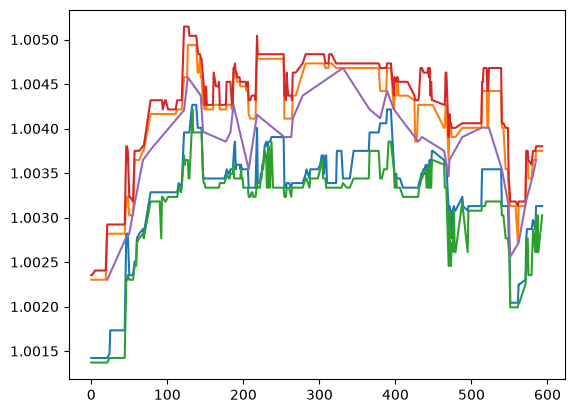

In [9]:
plt.plot(example["seconds_in_bucket"], example["bid_price1"])
plt.plot(example["seconds_in_bucket"], example["ask_price1"])
plt.plot(example["seconds_in_bucket"], example["bid_price2"])
plt.plot(example["seconds_in_bucket"], example["ask_price2"])
plt.plot(example2["seconds_in_bucket"], example2["price"])
plt.show()

In [10]:
# 总共3830个time stamps，然后总共这5个stock会有一些缺失，但也不算很多。at most 15 time id missing on each stock.
time_counts = book_train.groupby(by = "stock_id")["time_id"].nunique()
time_counts[time_counts != time_counts.max()]

stock_id
100    3829
13     3829
38     3815
75     3829
80     3820
Name: time_id, dtype: int64

In [11]:
print(
    (book_train["ask_price1"] <= book_train["bid_price1"]).any(),
    (book_train["ask_price1"] >= book_train["ask_price2"]).any(),
    (book_train["bid_price1"] <= book_train["bid_price2"]).any()
)

False False False


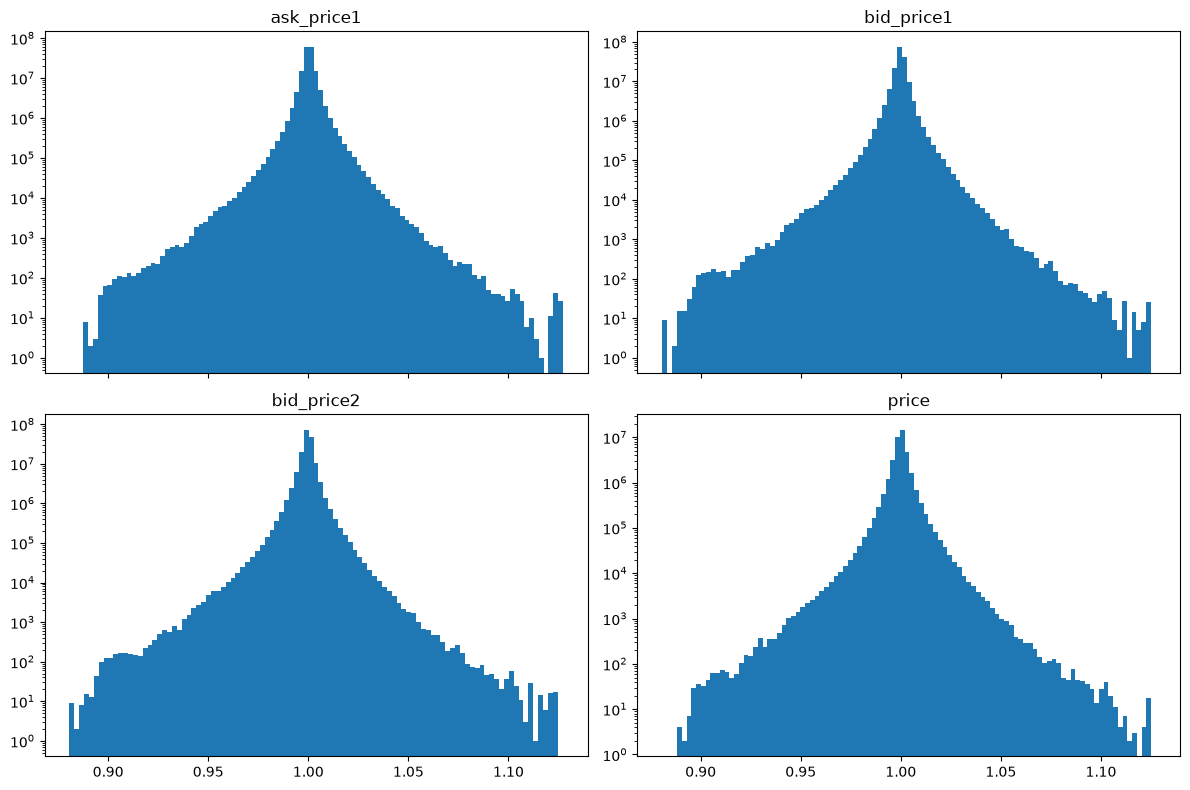

In [12]:
cols = [(book_train, "ask_price1"), (book_train, "bid_price1"),
        (book_train, "bid_price2"), (trade_train, "price")]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for ax, (df, col) in zip(axes.flat, cols):
    ax.hist(df[col], bins=100, log=True)
    ax.set_title(col)

plt.tight_layout()
plt.show()


In [13]:
print(book_train["seconds_in_bucket"].min(), book_train["seconds_in_bucket"].max())

0 599


array([[<Axes: title={'center': 'time_id'}>,
        <Axes: title={'center': 'seconds_in_bucket'}>],
       [<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'size'}>],
       [<Axes: title={'center': 'order_count'}>, <Axes: >]], dtype=object)

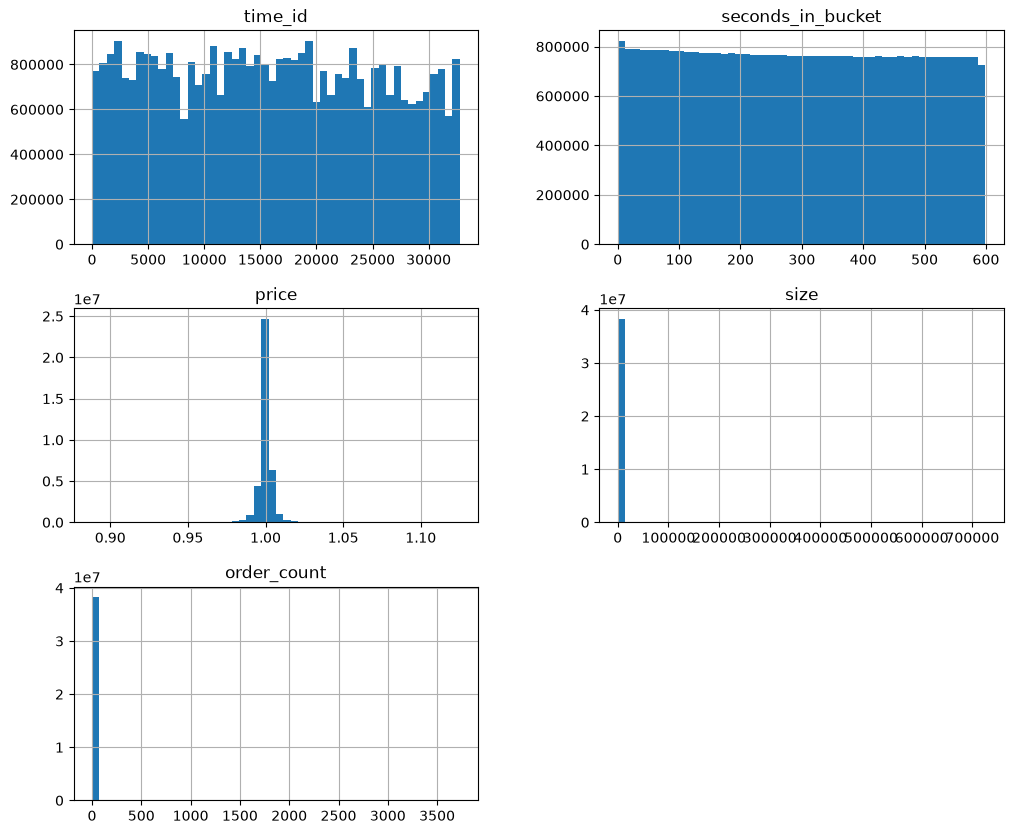

In [14]:
trade_train.hist(bins = 50, figsize=(12,10))

array([[<Axes: title={'center': 'time_id'}>,
        <Axes: title={'center': 'seconds_in_bucket'}>,
        <Axes: title={'center': 'bid_price1'}>],
       [<Axes: title={'center': 'ask_price1'}>,
        <Axes: title={'center': 'bid_price2'}>,
        <Axes: title={'center': 'ask_price2'}>],
       [<Axes: title={'center': 'bid_size1'}>,
        <Axes: title={'center': 'ask_size1'}>,
        <Axes: title={'center': 'bid_size2'}>],
       [<Axes: title={'center': 'ask_size2'}>, <Axes: >, <Axes: >]],
      dtype=object)

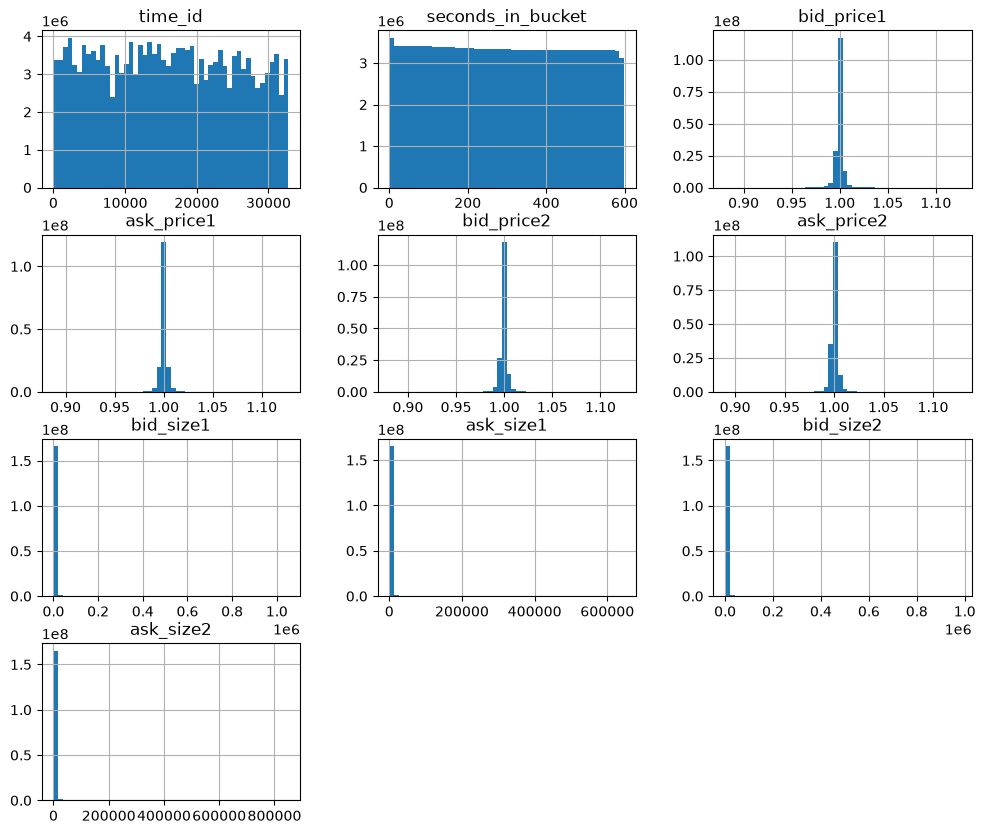

In [15]:
book_train.hist(bins = 50, figsize=(12,10))

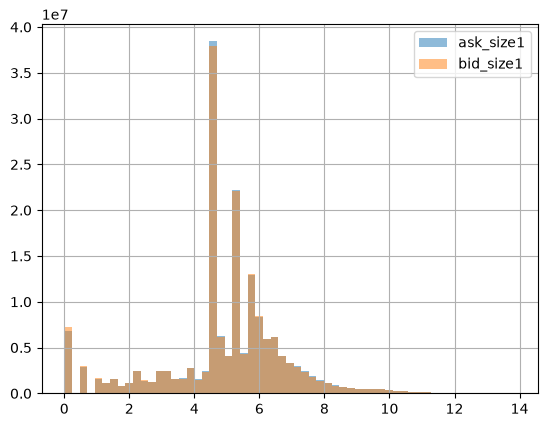

In [16]:
a = np.log(book_train["ask_size1"])
b = np.log(book_train["bid_size1"])
bins = np.linspace(0, max(a.max(), b.max()), 60)

a.hist(bins=bins, alpha=0.5, label="ask_size1")
b.hist(bins=bins, alpha=0.5, label="bid_size1")
plt.legend()


In [17]:
print(
    (book_train["ask_size1"] > book_train["ask_size2"]).mean(),
    (book_train["bid_size1"] > book_train["bid_size2"]).mean(),
    (book_train["ask_size1"]  > book_train["bid_size1"]).mean(),
    (book_train["ask_size1"] + book_train["ask_size2"] > book_train["bid_size1"] + book_train["bid_size2"]).mean()
)

0.4113866962580329 0.4108502045660818 0.46135721731606727 0.49056949785902265


array([[<Axes: title={'center': 'stock_id'}>,
        <Axes: title={'center': 'time_id'}>],
       [<Axes: title={'center': 'target'}>, <Axes: >]], dtype=object)

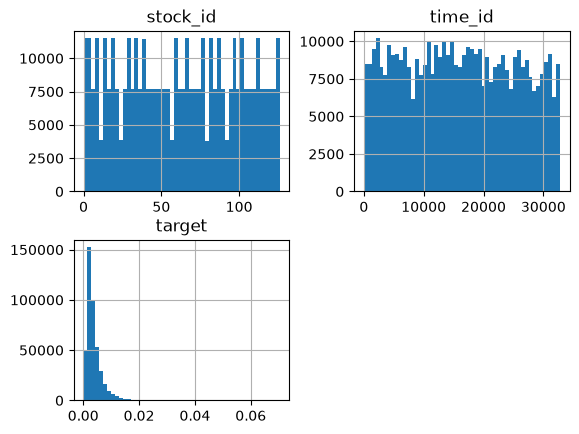

In [18]:
target.hist(bins = 50)

<Axes: >

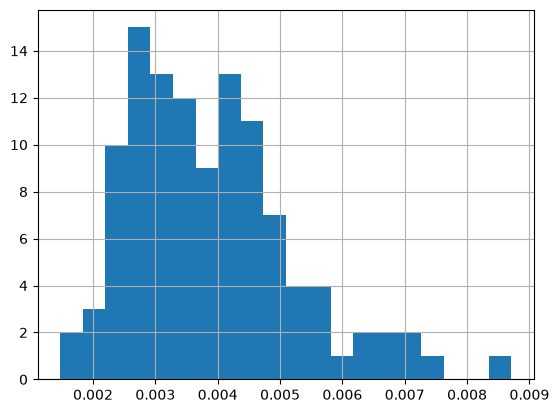

In [22]:
target.groupby("stock_id")["target"].mean().hist(bins = 20)

<Axes: >

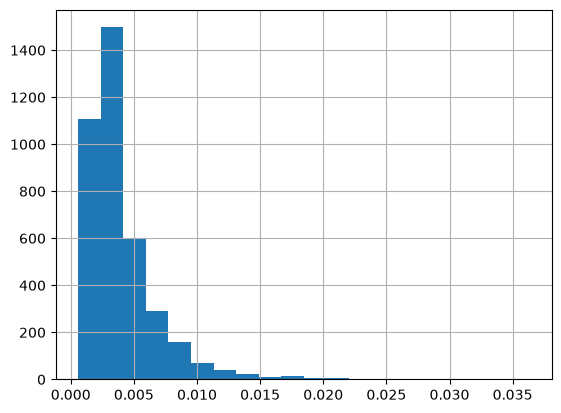

In [24]:
target.query("stock_id == 0")["target"].hist(bins = 20)

In [29]:
b = book_train

# 两档总挂单量。注意：算 WAP1 不用这个，用的是一档的买卖量之和
b["tot_size"] = b["bid_size1"] + b["bid_size2"] + b["ask_size1"] + b["ask_size2"]

# WAP（加权中间价）：买价乘卖量，卖价乘买量，权重是交叉的
# 卖单多，说明价格更可能往下走，所以 WAP 更靠近买价；买单多则更靠近卖价
b["wap1"] = ((b["bid_price1"] * b["ask_size1"] + b["ask_price1"] * b["bid_size1"])
             / (b["bid_size1"] + b["ask_size1"])).astype("float32")

b["log_wap1"] = np.log(b["wap1"])
b["log_ret1"] = b.groupby(by = ["stock_id", "time_id"], observed=True)["log_wap1"].diff(1)

In [34]:
def realized_vol(series):
    return np.sqrt(np.sum(np.square(series)))

rv = b.groupby(by = ["stock_id", "time_id"], observed=True)["log_ret1"].agg(realized_vol).reset_index()

rv.rename(columns={"log_ret1":"rv1"}, inplace=True)

rv

,stock_id,time_id,rv1
0,0,5,0.004499
1,0,11,0.001204
2,0,16,0.002369
3,0,31,0.002574
4,0,62,0.001895
...,...,...,...
428927,99,32751,0.001436
428928,99,32753,0.001795
428929,99,32758,0.001658
428930,99,32763,0.002213


In [36]:
combined = pd.merge(target, rv, how = "outer", on = ["stock_id", "time_id"])
combined.isna().any()

stock_id    False
time_id     False
target      False
rv1         False
dtype: bool

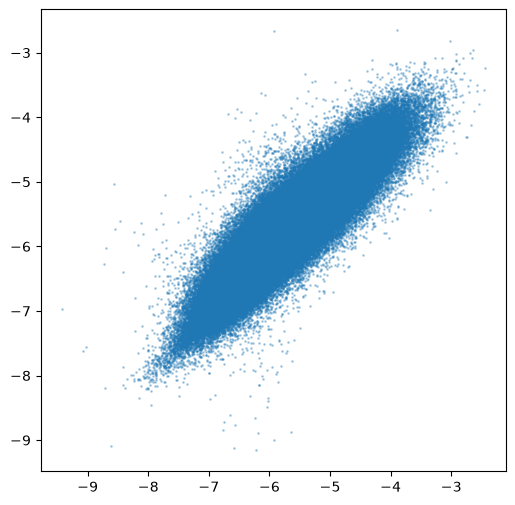

In [55]:
plt.figure(figsize=(6, 6))
plt.scatter(np.log(combined["rv1"]), np.log(combined["target"]), s=1, alpha=0.3)
plt.show()


In [59]:
combined[["target", "rv1"]].corr()

,target,rv1
target,1.000000,0.873777
rv1,0.873777,1.000000


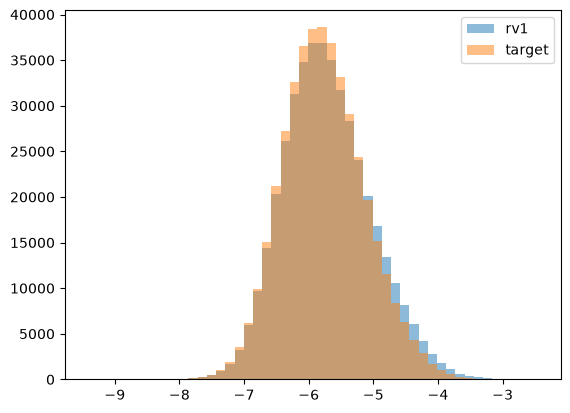

In [71]:
a = np.log(combined["rv1"])
b = np.log(combined["target"])
bins = np.linspace(min(min(a), min(b)), max(max(a), max(b)), 50)
plt.hist(a, bins = bins, alpha = 0.5, label = "rv1",)
plt.hist(b, bins = bins, alpha = 0.5, label = "target")
plt.legend()
plt.show()

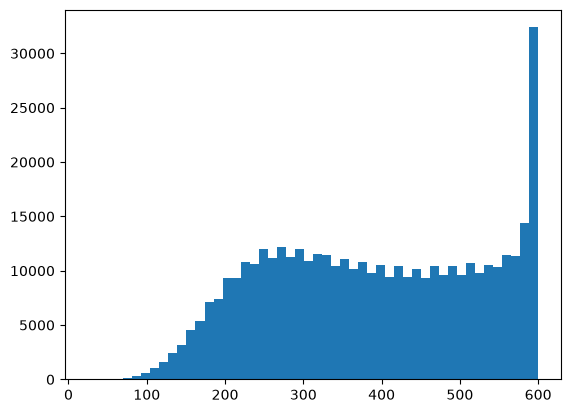

In [74]:
# how many datapoints in each window? each 10 min window

num_data_per_window = book_train.groupby(["stock_id", "time_id"], observed=True)["ask_price1"].count()
plt.hist(num_data_per_window, bins = 50)
plt.show()

In [81]:
num_data_per_window.describe([0.00001, 0.0001, 0.001, 0.01,0.99])

count     428932.000000
mean         389.929614
std          135.833693
min           24.000000
0.001%        40.000000
0.01%         60.893100
0.1%          88.000000
1%           130.000000
99%          600.000000
max          600.000000
Name: ask_price1, dtype: float64

In [ ]:
# 看不同股票之间的关系。就是PCA，corr heatmap什么的

